## 四、LIF 对照实验（Section 1 · Part 3）

### 实验 3 · 膜时间常数

固定电流 2.0 nA 和阈值 −50 mV，分别设 $\tau_m=10$、$20$、$40\,\mathrm{ms}$。
左图是恒流仿真，右图用无输入时的解析衰减说明不同 $\tau_m$ 的物理意义。

静息与重置电位为 −65 mV，膜电阻为 10 MΩ，不应期为 2 ms。步长为 0.1 ms，仿真时长为 2 s。左图展示前 200 ms，脉冲计数和平均发放率使用完整仿真。

可以从本节的路径设置单元格开始依次运行。对照图保存至 lif/output/experiment3/03_membrane_time_constant.png。 [作业第 3 页](../homework-2.pdf#page=3)

In [8]:
import sys
from pathlib import Path

project_root = next(
    directory
    for directory in (Path.cwd(), *Path.cwd().parents)
    if (directory / "lif" / "model.py").is_file()
)
sys.path.insert(0, str(project_root))

| 参数档位 | 脉冲总数 | 平均发放率 (Hz) | 首发 (ms) | 平均脉冲间隔 (ms) |
| :--- | ---: | ---: | ---: | ---: |
| 10 ms | 126 | 63.0 | 13.8 | 15.8 |
| 20 ms | 67 | 33.5 | 27.7 | 29.7 |
| 40 ms | 34 | 17.0 | 55.4 | 57.4 |

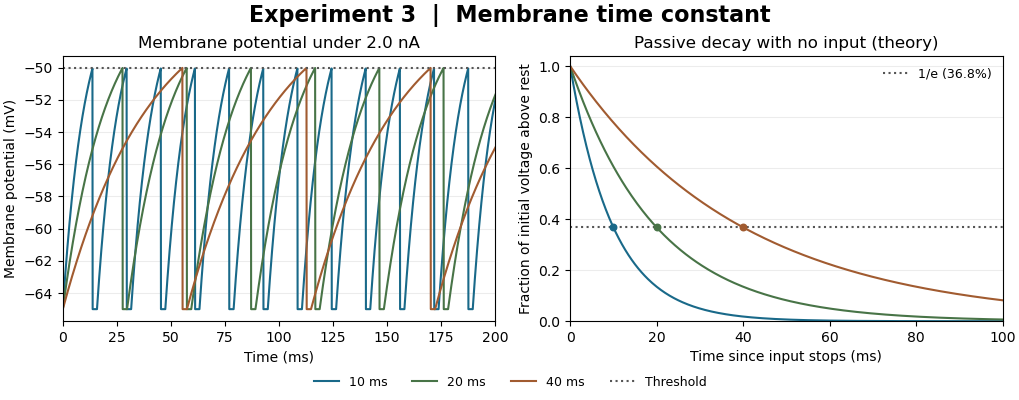

In [9]:
from dataclasses import replace

import matplotlib.pyplot as plt
import numpy as np
from IPython.display import Markdown, display

from lif.model import SimulationParameters, simulate_experiment

baseline = SimulationParameters(
    mode="constant",
    current=2.0,
    threshold=-50.0,
    rest=-65.0,
    resistance=10.0,
    refractory=2.0,
    dt=0.1,
    duration=2000.0,
)
table = [
    "| 参数档位 | 脉冲总数 | 平均发放率 (Hz) | 首发 (ms) | 平均脉冲间隔 (ms) |",
    "| :--- | ---: | ---: | ---: | ---: |",
]
fig, (voltage_ax, decay_ax) = plt.subplots(
    1, 2, figsize=(10.2, 4.0), layout="constrained"
)
fig.suptitle("Experiment 3  |  Membrane time constant", fontsize=16, weight="bold")
decay_time = np.linspace(0, 100, 401)
colors = ("#196989", "#487447", "#a15b30")

for tau_ms, color in zip((10, 20, 40), colors, strict=True):
    parameters = replace(baseline, tau=tau_ms)
    signals = simulate_experiment(parameters)
    spike_times = signals["time_ms"][signals["spikes"].astype(bool)]
    count = spike_times.size
    mean_rate_hz = count * 1000 / parameters.duration
    first_spike = f"{spike_times[0]:.1f}" if count else "—"
    mean_isi = f"{np.diff(spike_times).mean():.1f}" if count > 1 else "—"
    table.append(
        f"| {tau_ms} ms | {count} | {mean_rate_hz:.1f} | {first_spike} | {mean_isi} |"
    )
    voltage_ax.plot(
        signals["time_ms"], signals["voltage"], color=color, label=f"{tau_ms} ms"
    )
    decay_ax.plot(decay_time, np.exp(-decay_time / tau_ms), color=color)
    decay_ax.scatter(tau_ms, np.exp(-1), color=color, s=22, zorder=3)

voltage_ax.axhline(
    baseline.threshold, color="#555555", linestyle=":", label="Threshold"
)
voltage_ax.set(
    title="Membrane potential under 2.0 nA",
    xlabel="Time (ms)",
    ylabel="Membrane potential (mV)",
    xlim=(0, 200),
)
fig.legend(
    *voltage_ax.get_legend_handles_labels(),
    loc="outside lower center",
    ncols=4,
    frameon=False,
    fontsize=9,
)
decay_ax.axhline(np.exp(-1), color="#555555", linestyle=":", label="1/e (36.8%)")
decay_ax.set(
    title="Passive decay with no input (theory)",
    xlabel="Time since input stops (ms)",
    ylabel="Fraction of initial voltage above rest",
    xlim=(0, 100),
    ylim=(0, 1.04),
)
decay_ax.legend(frameon=False, fontsize=9)
for ax in (voltage_ax, decay_ax):
    ax.grid(axis="y", alpha=0.24)

figure_path = project_root / "lif/output/experiment3/03_membrane_time_constant.png"
figure_path.parent.mkdir(parents=True, exist_ok=True)
fig.savefig(figure_path, dpi=180, facecolor="white")
display(Markdown("\n".join(table)))
plt.show()

1. **积分和泄漏。** 改变 $\tau_m$ 会改变电位接近稳态和返回静息的速度。
   在相同的恒流与电阻下，三档的发放前稳态电位均为 −45 mV。
2. **轨迹、首发和发放率。** $\tau_m$ 从 10 ms 增至 20 和 40 ms，首发由 13.8 ms
   推迟到 27.7 和 55.4 ms，平均发放率依次为 63.0、33.5、17.0 Hz。电位上升变慢，
   相邻脉冲之间也隔得更久。
3. **膜电路的物理意义。** 膜相当于一个带并联漏电阻 $R$ 的电容 $C$，
   $\tau_m=RC$。停止输入后，$V-V_{\mathrm{rest}}$ 按 $e^{-t/\tau_m}$ 衰减，
   经过一个 $\tau_m$ 剩下初值的约 36.8%。恒流接通后，若尚未到达阈值，经过一个 $\tau_m$ 会走过到稳态电位差的约 63.2%。
   固定 $R=10\,\mathrm{M\Omega}$，这里的三个 $\tau_m$ 等效于 $C=1$、$2$、$4\,\mathrm{nF}$。